# TD Discrétisation - M2 IGAST - CORRECTION

## Feuillus et conifères

Part des feuillus et part des conifères dans la surface forestière de chaque département

- Comparaison relative pour les quantiles, Q6 et la moyenne et l'écart-type. Les classes sont calculées sur chaque série
- Comparaison absolue pour Jenks et les amplitudes égales. Les classes sont communes aux deux séries

In [1]:
import geopandas as gpd
import mapclassify as mc
import mappyng as mp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import inv_boxcox
from scipy.stats import boxcox
from IPython.display import HTML

URL = "https://github.com/fbxyz/M2_IGAST/raw/master/data/{}_3857.geojson"

deps = gpd.read_file(URL.format("DEP_FORET")).to_crs(2154)
europe = gpd.read_file(URL.format("UE_GEN3")).to_crs(2154)
regions = deps.dissolve("insee_reg").reset_index()
france = deps.dissolve()

deps["Feuillus (%)"] = deps["p_feuillus"].map(lambda v: f"{v:.1f}".replace(".", ","))
deps["Conifères (%)"] = deps["p_conifere"].map(lambda v: f"{v:.1f}".replace(".", ","))

SERIES = {"p_feuillus": ("Part des feuillus", "Feuillus (%)"),
          "p_conifere": ("Part des conifères", "Conifères (%)")}
COULEURS = {"p_feuillus": "#74c476", "p_conifere": "#006d2c"}

ERROR 1: PROJ: proj_create_from_database: Open of /home/florian/miniconda3/envs/geo/share/proj failed


## Analyse univariée

### Valeurs centrales et dispersion

In [2]:
def resume(v):
    q1, mediane, q3 = np.percentile(v, [25, 50, 75])
    return {
        "Effectif": len(v),
        "Minimum": v.min(),
        "1er quartile": q1,
        "Médiane": mediane,
        "Moyenne": v.mean(),
        "3e quartile": q3,
        "Maximum": v.max(),
        "Etendue": v.max() - v.min(),
        "IQR": q3 - q1,
        "Ecart-type": v.std(),
    }


def virgule(v, decimales):
    return f"{v:.{decimales}f}".replace(".", ",")


def p_valeur(p):
    return "< 0,001" if p < 0.001 else virgule(p, 3)


def qq(ax, x, couleur, titre):
    stats.probplot(x, dist="norm", plot=ax)
    points, droite = ax.get_lines()
    points.set(markerfacecolor=couleur, markeredgecolor="#333333", markeredgewidth=0.5, markersize=5)
    droite.set(color="black", lw=1)
    ax.set(title=titre, xlabel="Quantiles théoriques (loi normale)", ylabel="Valeurs observées")


resume_series = pd.DataFrame({nom: resume(deps[col]) for col, (nom, _) in SERIES.items()})
resume_series.style.format(lambda v: virgule(v, 1)).format(
    lambda v: f"{v:.0f}", subset=pd.IndexSlice[["Effectif"], :])

,Part des feuillus,Part des conifères
Effectif,96,96
Minimum,"14,2","0,0"
1er quartile,"58,0","6,7"
Médiane,"76,7","13,1"
Moyenne,"70,3","16,8"
3e quartile,"84,7","23,1"
Maximum,"98,6","60,4"
Etendue,"84,4","60,4"
IQR,"26,7","16,3"
Ecart-type,"20,5","13,9"


### Distribution

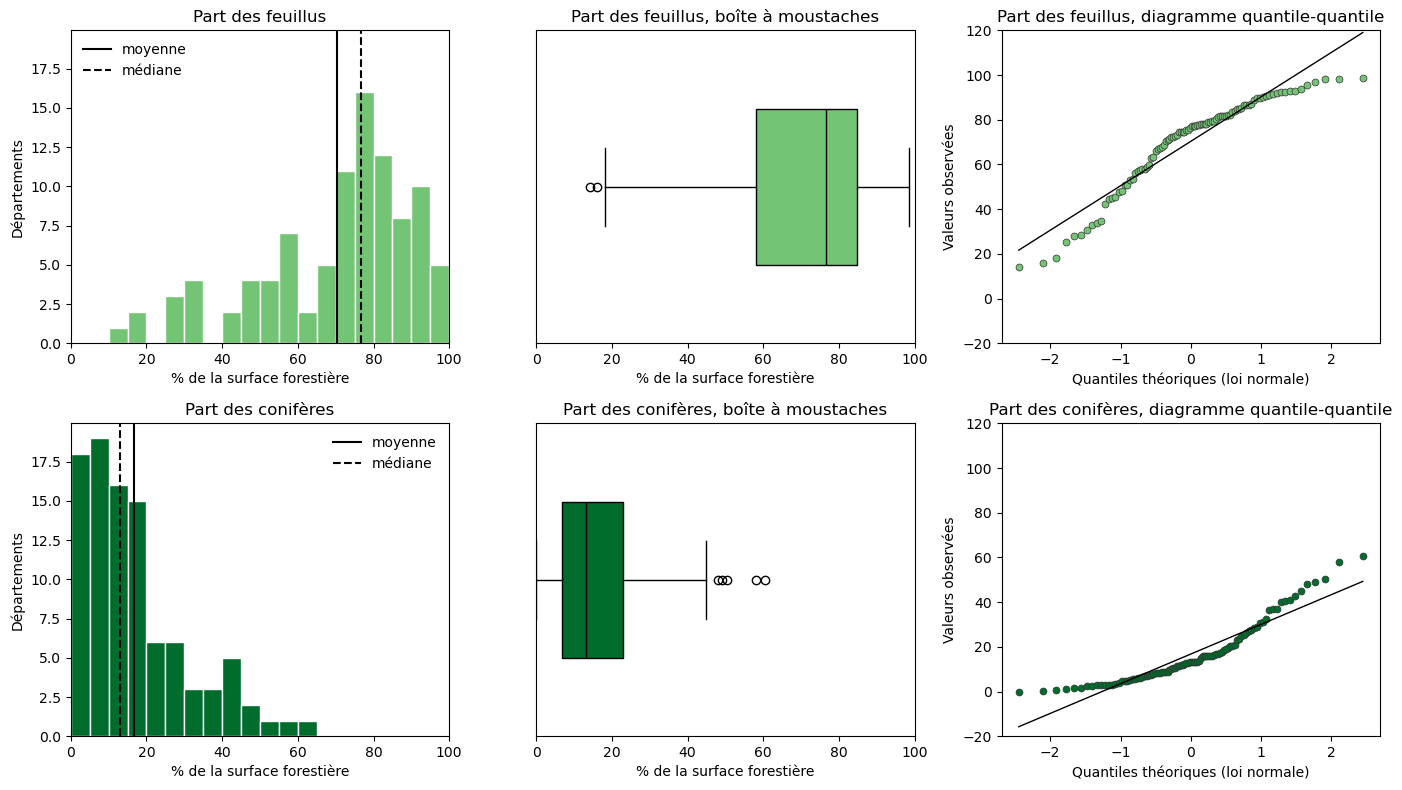

In [3]:
# mêmes axes pour les deux séries
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex="col", sharey="col")
for ligne, (col, (nom, _)) in zip(axes, SERIES.items()):
    v = deps[col]
    ax_h, ax_b, ax_q = ligne
    ax_h.hist(v, bins=np.arange(0, 101, 5), color=COULEURS[col], edgecolor="white")
    ax_h.set_xlim(0, 100)
    ax_h.axvline(v.mean(), color="black", lw=1.5, label="moyenne")
    ax_h.axvline(v.median(), color="black", lw=1.5, ls="--", label="médiane")
    ax_h.set(title=nom, xlabel="% de la surface forestière", ylabel="Départements")
    ax_h.legend(frameon=False)
    ax_b.boxplot(v, vert=False, widths=0.5, patch_artist=True,
                 boxprops={"facecolor": COULEURS[col]}, medianprops={"color": "black"})
    ax_b.set(title=f"{nom}, boîte à moustaches", xlabel="% de la surface forestière", yticks=[])
    qq(ax_q, v, COULEURS[col], f"{nom}, diagramme quantile-quantile")
    ax_b.set_xlim(0, 100)
    ax_q.set_ylim(-20, 120)
for ax in axes.flat:
    ax.tick_params(labelbottom=True, labelleft=True)
plt.tight_layout()

### Asymétrie et normalité

Test d'asymétrie (H0 : coefficient d'asymétrie nul) et test de Shapiro-Wilk (H0 : la série suit une loi normale), au seuil de 5 %.

In [4]:
def tests(v):
    return {
        "Asymétrie": stats.skew(v),
        "Aplatissement": stats.kurtosis(v),
        "Test d'asymétrie, p": stats.skewtest(v).pvalue,
        "Shapiro-Wilk, W": stats.shapiro(v).statistic,
        "Shapiro-Wilk, p": stats.shapiro(v).pvalue,
    }


P_VALEURS = ["Test d'asymétrie, p", "Shapiro-Wilk, p"]


def tableau_tests(df):
    return df.style.format(lambda v: virgule(v, 3)).format(p_valeur, subset=pd.IndexSlice[P_VALEURS, :])


tableau_tests(pd.DataFrame({nom: tests(deps[col]) for col, (nom, _) in SERIES.items()}))

,Part des feuillus,Part des conifères
Asymétrie,"-0,973","1,203"
Aplatissement,"0,228","0,851"
"Test d'asymétrie, p","< 0,001","< 0,001"
"Shapiro-Wilk, W","0,911","0,882"
"Shapiro-Wilk, p","< 0,001","< 0,001"


### Avant et après Box-Cox

Un département n'a aucun conifère et Box-Cox n'accepte que des valeurs positives. Les deux séries sont décalées d'un point avant la transformation.

In [5]:
def box_cox(v):
    return boxcox(np.asarray(v) + 1)


comparaison = {}
for col, (nom, _) in SERIES.items():
    t, lam = box_cox(deps[col])
    for etat, x in (("brute", deps[col]), (f"Box-Cox (λ = {lam:.2f})".replace(".", ","), t)):
        comparaison[(nom, etat)] = tests(x)

tableau_tests(pd.DataFrame(comparaison))

In [6]:
transformees = {nom: box_cox(deps[col])[0] for col, (nom, _) in SERIES.items()}

pd.DataFrame({nom: resume(t) for nom, t in transformees.items()}).style.format(lambda v: virgule(v, 2)).format(
    lambda v: f"{v:.0f}", subset=pd.IndexSlice[["Effectif"], :])

,Part des feuillus,Part des conifères
Effectif,96,96
Minimum,"142,30","0,00"
1er quartile,"2443,99","2,63"
Médiane,"4355,25","3,67"
Moyenne,"3976,80","3,65"
3e quartile,"5344,51","4,73"
Maximum,"7327,12","6,94"
Etendue,"7184,82","6,94"
IQR,"2900,52","2,10"
Ecart-type,"1895,74","1,56"


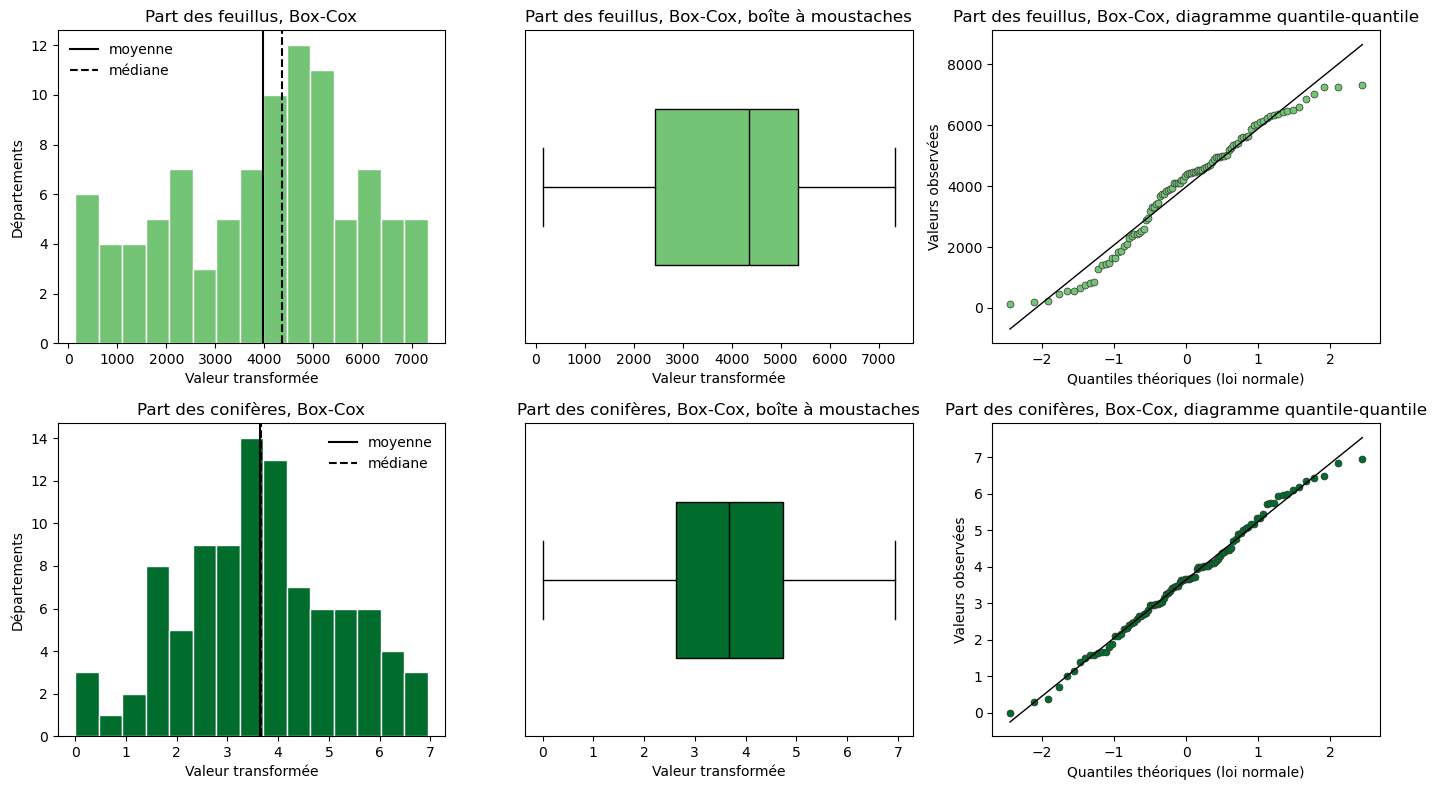

In [7]:
# chaque série dans son unité après transformation (λ différents)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ligne, (col, (nom, _)) in zip(axes, SERIES.items()):
    t = transformees[nom]
    ax_h, ax_b, ax_q = ligne
    ax_h.hist(t, bins=15, color=COULEURS[col], edgecolor="white")
    ax_h.axvline(t.mean(), color="black", lw=1.5, label="moyenne")
    ax_h.axvline(np.median(t), color="black", lw=1.5, ls="--", label="médiane")
    ax_h.set(title=f"{nom}, Box-Cox", xlabel="Valeur transformée", ylabel="Départements")
    ax_h.legend(frameon=False)
    ax_b.boxplot(t, vert=False, widths=0.5, patch_artist=True,
                 boxprops={"facecolor": COULEURS[col]}, medianprops={"color": "black"})
    ax_b.set(title=f"{nom}, Box-Cox, boîte à moustaches", xlabel="Valeur transformée", yticks=[])
    qq(ax_q, t, COULEURS[col], f"{nom}, Box-Cox, diagramme quantile-quantile")
plt.tight_layout()

## Fond de carte

In [8]:
BBOX = [90000, 6040000, 1280000, 7150000]
SOURCE = "Source : IGN, 2024 - F. Bayer"


def fond():
    return (
        mp.Map(europe, bbox=BBOX, width=900, height=1000, padding=25,
               facecolor="#B9D9EB", border_radius=10,
               box_shadow={"dx": 3, "dy": 3, "blur": 6, "opacity": 0.2})
        + mp.Graticule(step=2, stroke="#ffffff", opacity=0.9, stroke_width=0.7)
        + mp.Basemap()
        + mp.Vector(regions, stroke="#4d4d4d", stroke_width=0.4)
        + mp.DropShadow(europe, query="code_pays_ == 'FRA'")
        + mp.Vector(france, fill="none", stroke="#404040", stroke_width=1.2, position="top")
        + mp.ScaleBar(length=100000, label="100 km", position=(0.55, 0.855), opacity=0.8)
        + mp.Source(SOURCE)
    )


def carte(colonne, methode, sous_titre, num_classes=None, decimales=1, couleurs="Greens"):
    titre, infobulle = SERIES[colonne]
    options = {"num_classes": num_classes} if num_classes else {}
    return (
        fond()
        + mp.Choropleth(deps, column=colonne, method=methode, cmap=couleurs, stroke="white",
                        stroke_width=0.6, border_contrast=True, **options,
                        legend=mp.Legend("Part dans la surface forestière (%)", decimals=decimales,
                                         decimal_sep=",", orientation="horizontal"))
        + mp.Title(titre, subtitle=f"{sous_titre}, 2024")
        + mp.Tooltip(["LIB_GEO", infobulle], aliases={"LIB_GEO": "Département"})
    )


def cote_a_cote(a, b):
    svgs = "".join(f"<div style='flex:1'>{c.to_interactive().svg}</div>" for c in (a, b))
    return HTML("<style>.paire svg{width:100%;height:auto}</style>"
                f"<div class='paire' style='display:flex;gap:12px'>{svgs}</div>")

## 1 - Quartiles (comparaison relative)

In [9]:
cote_a_cote(carte("p_feuillus", "Quantiles", "Quartiles", 4),
            carte("p_conifere", "Quantiles", "Quartiles", 4))

## 2 - Quintiles (comparaison relative)

In [10]:
cote_a_cote(carte("p_feuillus", "Quantiles", "Quintiles", 5),
            carte("p_conifere", "Quantiles", "Quintiles", 5))

## 3 - Q6 (comparaison relative)

In [11]:
def q6(colonne):
    return list(np.quantile(deps[colonne], [0, 0.05, 0.25, 0.5, 0.75, 0.95, 1]))


cote_a_cote(carte("p_feuillus", q6("p_feuillus"), "Q6"),
            carte("p_conifere", q6("p_conifere"), "Q6"))

## 4 - Moyenne et écart-type (comparaison relative)

In [12]:
# moyenne au centre de la classe centrale, limites à m ± 0,5σ et m ± 1,5σ
# sous la moyenne en violet, au-dessus en orange, la classe de la moyenne en neutre
ECARTS = ["#542788", "#998ec3", "#f7f7f7", "#f1a340", "#b35806"]


def ecart_type(v, transformee=None, retour=None):
    """Bornes et couleurs. Avec une transformation, les bornes sont calculées sur la série
    transformée puis ramenées dans l'unité d'origine. Les bornes hors de la série sont retirées."""
    t = v if transformee is None else transformee
    m, s = t.mean(), t.std()
    limites = [m + k * s for k in (-1.5, -0.5, 0.5, 1.5)]
    gardees = [i for i, b in enumerate(limites) if t.min() < b < t.max()]
    bornes = [b if retour is None else float(retour(b)) for b in (limites[i] for i in gardees)]
    return [v.min()] + bornes + [v.max()], ECARTS[gardees[0]:gardees[-1] + 2]


def carte_ecart_type(colonne, transformee=False):
    v = deps[colonne].to_numpy()
    if transformee:
        t, lam = box_cox(v)
        bornes, couleurs = ecart_type(v, t, lambda b: inv_boxcox(b, lam) - 1)
        sous_titre = f"Moyenne et écart-type après Box-Cox (λ = {lam:.2f})".replace(".", ",")
    else:
        bornes, couleurs = ecart_type(v)
        sous_titre = "Moyenne et écart-type"
    return carte(colonne, bornes, sous_titre, couleurs=couleurs)


cote_a_cote(carte_ecart_type("p_feuillus"), carte_ecart_type("p_conifere"))

## 5 - Moyenne et écart-type après Box-Cox (comparaison relative)

In [13]:
cote_a_cote(carte_ecart_type("p_feuillus", transformee=True),
            carte_ecart_type("p_conifere", transformee=True))

## 6 - Jenks, 5 classes (comparaison absolue)

In [14]:
# classes calculées sur les deux séries réunies
toutes = np.concatenate([deps["p_feuillus"], deps["p_conifere"]])


def jenks(k):
    return [toutes.min()] + list(mc.FisherJenks(toutes, k).bins)


cote_a_cote(carte("p_feuillus", jenks(5), "Jenks, 5 classes communes"),
            carte("p_conifere", jenks(5), "Jenks, 5 classes communes"))

## 7 - Jenks, 6 classes (comparaison absolue)

In [15]:
cote_a_cote(carte("p_feuillus", jenks(6), "Jenks, 6 classes communes"),
            carte("p_conifere", jenks(6), "Jenks, 6 classes communes"))

## 8 - Amplitudes égales (comparaison absolue)

In [16]:
EGALES = [0, 20, 40, 60, 80, 100]

cote_a_cote(carte("p_feuillus", EGALES, "Amplitudes égales, 5 classes de 20 points", decimales=0),
            carte("p_conifere", EGALES, "Amplitudes égales, 5 classes de 20 points", decimales=0))